In [31]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import yfinance as yf
import os

In [4]:
# --- 1. Definir los Tickers y el Rango de Fechas ---
# Esta es la lista de los 30 tickers que se usaron en tu guía
tickers = [
    'MMM', 'AXP', 'AAPL', 'BA', 'CAT', 'CVX', 'CSCO', 'KO', 'DIS',
    'XOM', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'MCD', 'MRK', 'MSFT',
    'NKE', 'PFE', 'PG', 'TRV', 'UNH', 'VZ', 'V', 'WMT', 'WBA'
]

In [58]:
# Rango de fechas basado en tu documento (de 2000-01-03 a 2019-02-06)
# Pedimos un día más en la fecha final para asegurar que incluya el último día.
start_date = '2000-01-03'
end_date = '2025-10-20'

In [59]:
print(f"Descargando datos para {len(tickers)} tickers...")

# 1. Intenta descargar TODOS los datos (sin seleccionar 'Adj Close' aún)
try:
    full_data = yf.download(tickers, start=start_date, end=end_date)

    # 2. Revisa si la descarga está vacía
    if full_data.empty:
        print("\n--- ERROR ---")
        print("La descarga falló. yfinance devolvió una tabla vacía.")
        print("Revisa tu conexión o intenta descargar un solo ticker (ej. 'AAPL') para aislar el problema.")
    
    else:
        print("\nDescarga completa. Extrayendo 'Adj Close'...")
        
        # 3. Si no está vacía, AHORA SÍ selecciona 'Adj Close'
        # Usamos .get() para más seguridad, aunque ['Adj Close'] debería funcionar
        data = full_data.get('Close')
        
        if data is None:
            print("Error: No se encontró la columna 'Adj Close' en los datos descargados.")
            print("Datos descargados:")
            print(full_data.head())
        else:
            # 4. Guardar el archivo (sólo si todo salió bien)
            output_dir = 'inputs'
            file_path = os.path.join(output_dir, 'djia_adjusted_closes.csv')

            if not os.path.exists(output_dir):
                os.makedirs(output_dir)

            data.to_csv(file_path)
            print(f"\n¡Éxito! Datos guardados en: {file_path}")
            
            print("\nVerificación:")
            print(data.head())

except Exception as e:
    print(f"\nOcurrió un error inesperado durante la descarga: {e}")

Descargando datos para 28 tickers...


C:\Users\magal\AppData\Local\Temp\ipykernel_26496\429222304.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  full_data = yf.download(tickers, start=start_date, end=end_date)
[*********************100%***********************]  28 of 28 completed


Descarga completa. Extrayendo 'Adj Close'...

¡Éxito! Datos guardados en: inputs\djia_adjusted_closes.csv

Verificación:
Ticker          AAPL        AXP         BA        CAT       CSCO        CVX  \
Date                                                                          
2000-01-03  0.840094  32.323582  25.940285  12.574044  35.148067  16.052578   
2000-01-04  0.769266  31.103094  25.899950  12.412425  33.176189  16.052578   
2000-01-05  0.780523  30.313133  27.513643  12.703341  33.074566  16.340525   
2000-01-06  0.712977  30.930693  27.796049  13.349820  32.525684  17.036366   
2000-01-07  0.746751  31.381014  28.602890  13.786196  34.436573  17.336306   

Ticker            DIS         GS         HD        IBM  ...       NKE  \
Date                                                    ...             
2000-01-03  22.736223  61.663673  38.163891  57.730179  ...  4.499920   
2000-01-04  24.068050  57.779686  36.151405  55.770561  ...  4.254470   
2000-01-05  25.066925  55.073978

In [60]:
# --- 4. Verificar (Opcional) ---
# Leemos el archivo que acabamos de guardar para verificar
import pandas as pd
df_verificacion = pd.read_csv(file_path, index_col=0, parse_dates=True)
print("\nVerificación (primeras 5 filas del archivo guardado):")
print(df_verificacion.head())


Verificación (primeras 5 filas del archivo guardado):
                AAPL        AXP         BA        CAT       CSCO        CVX  \
Date                                                                          
2000-01-03  0.840094  32.323582  25.940285  12.574044  35.148067  16.052578   
2000-01-04  0.769266  31.103094  25.899950  12.412425  33.176189  16.052578   
2000-01-05  0.780523  30.313133  27.513643  12.703341  33.074566  16.340525   
2000-01-06  0.712977  30.930693  27.796049  13.349820  32.525684  17.036366   
2000-01-07  0.746751  31.381014  28.602890  13.786196  34.436573  17.336306   

                  DIS         GS         HD        IBM  ...       NKE  \
Date                                                    ...             
2000-01-03  22.736223  61.663673  38.163891  57.730179  ...  4.499920   
2000-01-04  24.068050  57.779686  36.151405  55.770561  ...  4.254470   
2000-01-05  25.066925  55.073978  36.883213  57.730179  ...  4.499920   
2000-01-06  24.068050  57.

Datos cargados exitosamente.
Matriz de correlación calculada.


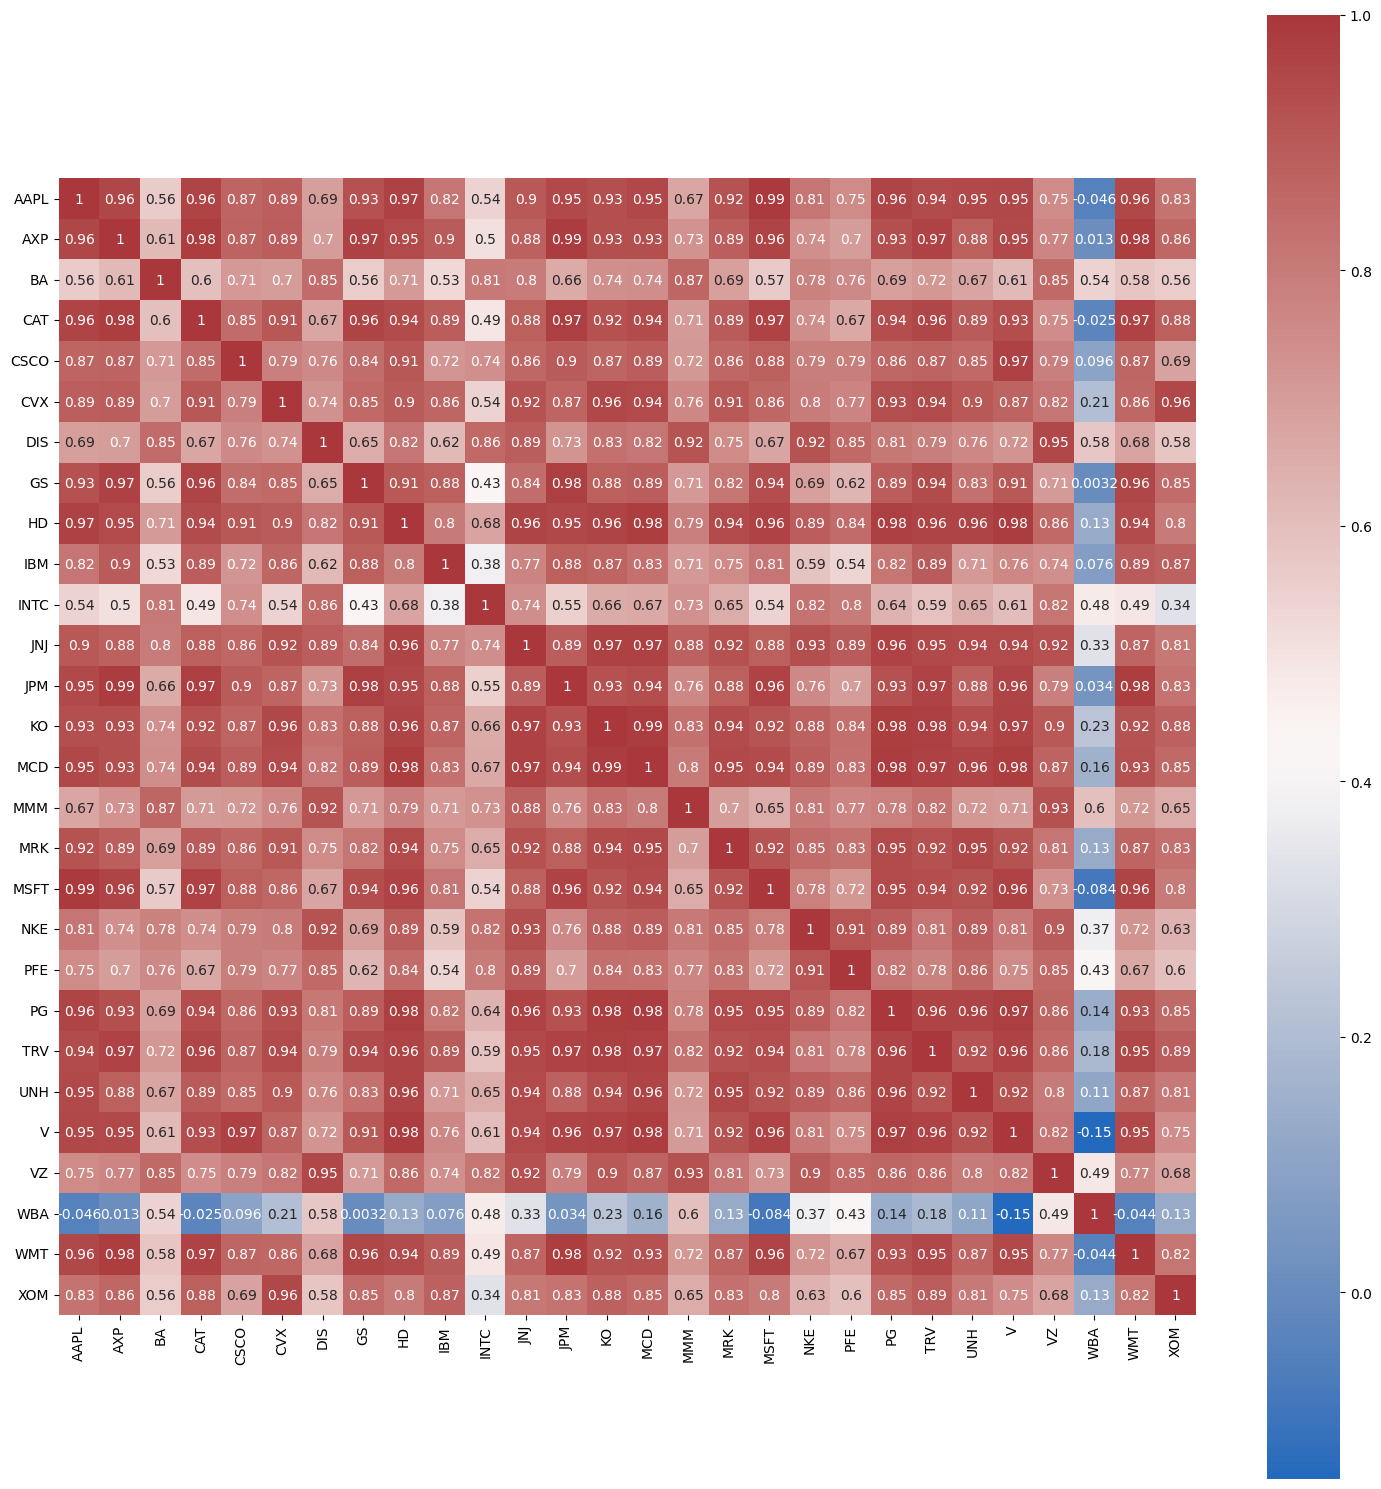

In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Cargar los datos (si no lo has hecho) ---
# Asume que tu archivo está en 'inputs/djia_adjusted_closes.csv'
try:
    dataset = pd.read_csv('inputs/djia_adjusted_closes.csv', index_col=0, parse_dates=True)
    print("Datos cargados exitosamente.")
except FileNotFoundError:
    print("Error: No se encontró el archivo 'inputs/djia_adjusted_closes.csv'")
    print("Asegúrate de haber ejecutado el script de descarga primero.")

# --- 2. Calcular la correlación ---
# Usamos el método .corr() en el DataFrame de precios
correlation = dataset.corr()

print("Matriz de correlación calculada.")

# --- 3. Generar el Heatmap ---
# Configuramos el tamaño de la figura para que sea grande y legible
plt.figure(figsize=(15, 15))

# Creamos el heatmap con seaborn
sns.heatmap(
    correlation,        # La matriz de correlación
    vmax=1,             # El valor máximo de la barra de color (1 es correlación perfecta)
    square=True,        # Asegura que cada celda sea un cuadrado
    annot=True,         # Muestra los números (coeficientes de correlación) en cada celda
    cmap='vlag'         # El mapa de color (rojo-blanco-azul) que usa la guía
)

# Ajustamos el layout para que no se corten las etiquetas
plt.tight_layout()

# Guardamos la imagen (opcional, pero recomendado)
plt.savefig('heatmap_correlacion_precios.png')

# Mostramos el gráfico
plt.show()

Rojo oscuro (cercano a 1): Significa que dos acciones están altamente correlacionadas. Cuando una sube, la otra casi siempre sube también.

Azul oscuro (cercano a -1): Correlación negativa. Cuando una sube, la otra baja (verás muy pocos de estos).

Blanco (cercano a 0): No hay correlación lineal.

In [62]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6488 entries, 2000-01-03 to 2025-10-17
Data columns (total 28 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    6488 non-null   float64
 1   AXP     6488 non-null   float64
 2   BA      6488 non-null   float64
 3   CAT     6488 non-null   float64
 4   CSCO    6488 non-null   float64
 5   CVX     6488 non-null   float64
 6   DIS     6488 non-null   float64
 7   GS      6488 non-null   float64
 8   HD      6488 non-null   float64
 9   IBM     6488 non-null   float64
 10  INTC    6488 non-null   float64
 11  JNJ     6488 non-null   float64
 12  JPM     6488 non-null   float64
 13  KO      6488 non-null   float64
 14  MCD     6488 non-null   float64
 15  MMM     6488 non-null   float64
 16  MRK     6488 non-null   float64
 17  MSFT    6488 non-null   float64
 18  NKE     6488 non-null   float64
 19  PFE     6488 non-null   float64
 20  PG      6488 non-null   float64
 21  TRV     6488 non-nu

In [63]:
# 1. Calcular la proporción de missings por columna
proporcion_missing = dataset.isnull().mean().sort_values(ascending=False)

# Vemos las 5 columnas con más missings
print("Proporción de Missings:")
print(proporcion_missing.head())

# 2. Crear una lista de columnas a eliminar
# (En la guía, el umbral es 0, pero 'V' es el único con muchos missings) [cite: 222]
drop_list = list(proporcion_missing[proporcion_missing > 0.4].index) # Eliminamos si falta más del 40%
print(f"\nColumnas a eliminar: {drop_list}")

# 3. Eliminar esas columnas del DataFrame
dataset = dataset.drop(labels=drop_list, axis=1)
print(f"\nForma de los datos después de eliminar: {dataset.shape}")

Proporción de Missings:
V       0.317972
WBA     0.005395
AAPL    0.000000
AXP     0.000000
CSCO    0.000000
dtype: float64

Columnas a eliminar: []

Forma de los datos después de eliminar: (6488, 28)


In [38]:
# 1. Calcular los retornos diarios (variación porcentual)
datareturns = dataset.pct_change(periods=1)

# 2. Ver el resultado
# El primer día (2000-01-03) no tiene un día anterior para comparar.
# Por lo tanto, su retorno es 'NaN' (Not a Number).
print("Datos transformados a retornos (notar el NaN en la primera fila):")
print(datareturns.head())

# 3. Eliminar la primera fila que contiene 'NaN'
datareturns = datareturns.dropna(how="any")

# ¡LISTO! Ahora tenemos una tabla limpia de retornos diarios.
print("\nDatos de retornos listos para el análisis:")
print(datareturns.head())

Datos transformados a retornos (notar el NaN en la primera fila):
                AAPL       AXP        BA       CAT      CSCO       CVX  \
Date                                                                     
2000-01-03       NaN       NaN       NaN       NaN       NaN       NaN   
2000-01-04 -0.084310 -0.037758 -0.001555 -0.012854 -0.056102  0.000000   
2000-01-05  0.014634 -0.025399  0.062305  0.023438 -0.003064  0.017937   
2000-01-06 -0.086539  0.020373  0.010263  0.050891 -0.016595  0.042585   
2000-01-07  0.047369  0.014559  0.029028  0.032687  0.058750  0.017605   

                 DIS        GS        HD       IBM  ...      MSFT       NKE  \
Date                                                ...                       
2000-01-03       NaN       NaN       NaN       NaN  ...       NaN       NaN   
2000-01-04  0.058578 -0.062986 -0.052732 -0.033944  ... -0.033780 -0.054545   
2000-01-05  0.041502 -0.046828  0.020243  0.035136  ...  0.010544  0.057692   
2000-01-06 -0.039848

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Crear el objeto StandardScaler
scaler = StandardScaler()

# 2. Ajustar el escalador a nuestros datos.
# Esto calcula la media (μ) y la desviación estándar (σ) de cada acción.
scaler.fit(datareturns)

# 3. Transformar (aplicar la fórmula)
rescaled_data_array = scaler.transform(datareturns)

# 4. Convertir el resultado (un array de numpy) de vuelta a un DataFrame
# Es importante mantener las fechas (index) y los tickers (columns)
rescaled_data = pd.DataFrame(rescaled_data_array, 
                            columns=datareturns.columns, 
                            index=datareturns.index)

# ¡LISTO! Los datos están limpios, transformados y escalados.
print("Datos estandarizados (listos para PCA):")
rescaled_data.head()

Datos estandarizados (listos para PCA):


,AAPL,AXP,BA,CAT,CSCO,CVX,DIS,GS,HD,IBM,...,MSFT,NKE,PFE,PG,TRV,UNH,VZ,WBA,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-04,-3.313785,-1.709758,-0.121974,-0.666727,-2.296342,-0.030172,3.078733,-2.711299,-2.739295,-2.099229,...,-1.774140,-2.933214,-2.402542,-1.478541,-0.759608,-0.696937,-2.091620,-2.164655,-2.504746,-1.283023
2000-01-05,0.522343,-1.157081,3.260109,1.123485,-0.137746,1.090149,2.173500,-2.021034,1.017053,2.143022,...,0.526597,3.018782,1.021751,-1.462053,-0.452540,-0.169254,2.122176,0.632188,-1.373993,3.562145
2000-01-06,-3.400179,0.889776,0.503928,2.477720,-0.688469,2.629633,-2.139121,1.807458,-2.476051,-1.073573,...,-1.759497,-0.316123,2.286625,3.456343,1.034601,1.800505,-0.345025,-1.705075,0.708272,3.376779
2000-01-07,1.791524,0.629760,1.497722,1.579760,2.378012,1.069417,-0.864801,0.141801,2.977752,-0.284048,...,0.657635,-0.040655,4.309078,6.017582,2.163145,5.881744,-0.492646,1.443603,5.006174,-0.216326
2000-01-10,-0.726919,0.602128,-0.786589,-1.651897,1.500557,-1.715904,8.063712,0.917310,-0.278246,2.420034,...,0.357766,0.859326,-0.135995,-0.389274,-1.034290,-0.926401,-0.359953,1.664918,-1.230356,-0.942822


In [40]:
# Definir el punto de corte (80% de los datos)
prop_training = int(len(rescaled_data) * 0.8)
print(f"El 80% de los datos equivale a {prop_training} filas.")

# --- Muestras para PCA (Datos Escalares) ---
# Datos de entrenamiento
X_train = rescaled_data[:prop_training]
# Datos de prueba
X_test = rescaled_data[prop_training:]

# --- Muestras para Backtesting (Datos Originales) ---
# Guardamos los retornos *originales* (sin escalar)
X_train_raw = datareturns[:prop_training]
X_test_raw = datareturns[prop_training:]

print(f"\nTotal de días: {len(rescaled_data)}")
print(f"Días de entrenamiento (train): {len(X_train)}")
print(f"Días de prueba (test): {len(X_test)}")

El 80% de los datos equivale a 3842 filas.

Total de días: 4803
Días de entrenamiento (train): 3842
Días de prueba (test): 961


In [41]:
from sklearn.decomposition import PCA

# 1. Crear una instancia del modelo PCA
# Por defecto, crea tantos componentes como variables (en nuestro caso, 27)
pca = PCA()

# 2. Entrenar el modelo con los datos de entrenamiento (escalados)
PrincipalComponent = pca.fit(X_train)
print("Modelo PCA entrenado.")

# 3. Analizar el resultado: Varianza Explicada
# Este atributo nos dice qué porcentaje de la varianza total 
# explica cada componente, en orden de importancia.
varianza_explicada = pca.explained_variance_ratio_

print(f"\nNúmero de componentes encontrados: {len(varianza_explicada)}")

# 4. Ver el hallazgo más importante
print(f"\nEl Componente Principal 1 (PC1) explica el {varianza_explicada[0] * 100:.2f}% de TODA la varianza.")
print(f"El Componente Principal 2 (PC2) explica el {varianza_explicada[1] * 100:.2f}% de la varianza.")
print(f"El Componente Principal 3 (PC3) explica el {varianza_explicada[2] * 100:.2f}% de la varianza.")

# Puedes imprimir el array completo si quieres
print("\nVarianza explicada por cada componente:")
print(varianza_explicada)

Modelo PCA entrenado.

Número de componentes encontrados: 27

El Componente Principal 1 (PC1) explica el 39.56% de TODA la varianza.
El Componente Principal 2 (PC2) explica el 7.23% de la varianza.
El Componente Principal 3 (PC3) explica el 4.07% de la varianza.

Varianza explicada por cada componente:
[0.39558564 0.07230976 0.04074486 0.04033744 0.03323667 0.02966171
 0.02869166 0.02626562 0.02513174 0.02397967 0.02365866 0.02287313
 0.02216118 0.0208258  0.02015619 0.01912134 0.01839939 0.01762762
 0.01709731 0.01614044 0.01557953 0.01482049 0.01376546 0.01362833
 0.01236168 0.01048405 0.00535465]


Varianza explicada por los primeros 5 componentes:
0    39.558564
1     7.230976
2     4.074486
3     4.033744
4     3.323667
dtype: float64

Varianza ACUMULADA por los primeros 5 componentes:
0    39.558564
1    46.789540
2    50.864026
3    54.897770
4    58.221437
dtype: float64


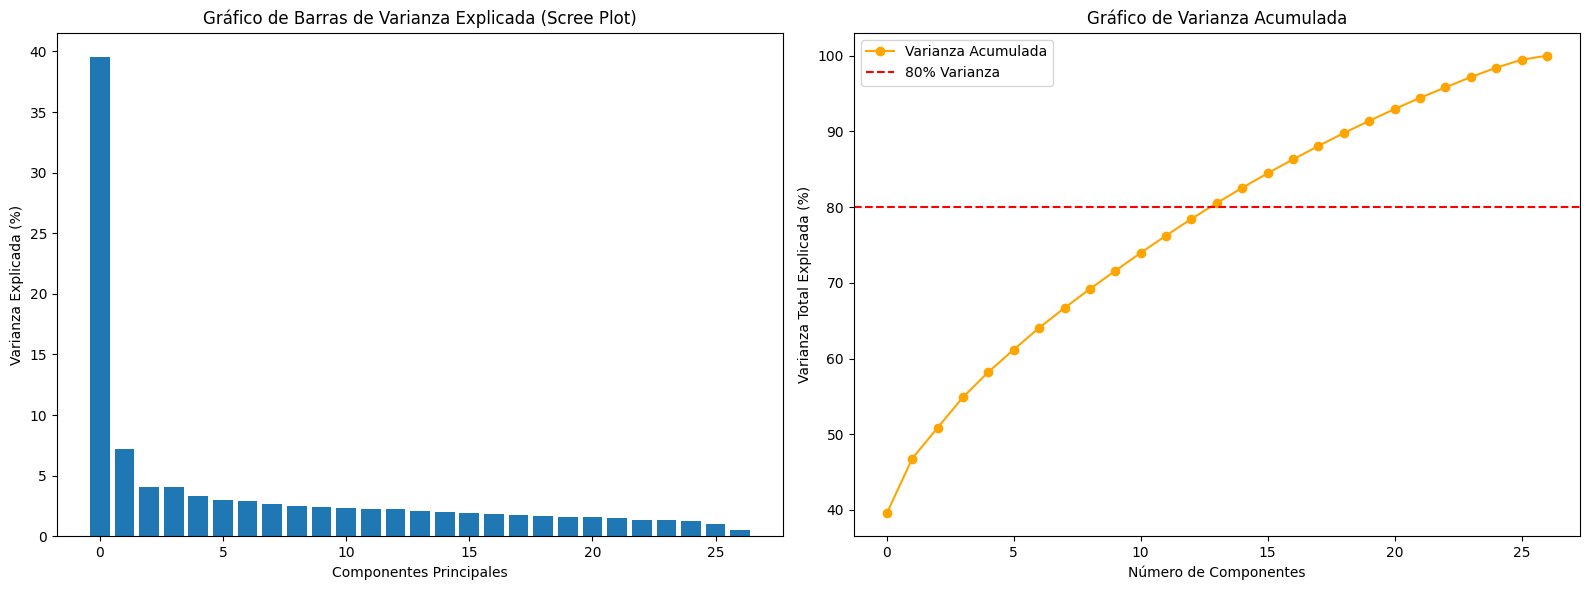

In [42]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Crear un DataFrame con la varianza explicada para facilitar el gráfico
# (multiplicamos por 100 para verlo en porcentaje)
varianza_explicada = pd.Series(pca.explained_variance_ratio_ * 100)
varianza_explicada_acumulada = varianza_explicada.cumsum()

print("Varianza explicada por los primeros 5 componentes:")
print(varianza_explicada.head())

print("\nVarianza ACUMULADA por los primeros 5 componentes:")
print(varianza_explicada_acumulada.head())

# 2. Crear la figura con 2 subplots (uno al lado del otro)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Gráfico 1: Varianza Individual (Scree Plot) ---
ax1.bar(
    varianza_explicada.index, 
    varianza_explicada,
    label='Varianza Individual'
)
ax1.set_title('Gráfico de Barras de Varianza Explicada (Scree Plot)')
ax1.set_xlabel('Componentes Principales')
ax1.set_ylabel('Varianza Explicada (%)')

# --- Gráfico 2: Varianza Acumulada ---
ax2.plot(
    varianza_explicada_acumulada, 
    label='Varianza Acumulada',
    color='orange',
    marker='o'
)
ax2.set_title('Gráfico de Varianza Acumulada')
ax2.set_xlabel('Número de Componentes')
ax2.set_ylabel('Varianza Total Explicada (%)')

# Añadir una línea en el 95% o 80% es común
ax2.axhline(y=80, color='r', linestyle='--', label='80% Varianza')
ax2.legend()

plt.tight_layout()
plt.show()

Cargas (pesos) de las acciones en los primeros 5 Componentes:
       AAPL       AXP        BA       CAT      CSCO       CVX       DIS  \
0  0.153540  0.240048  0.191909  0.211105  0.189097  0.200847  0.215480   
1  0.298631  0.088281 -0.025739  0.027675  0.362203 -0.149286  0.084777   
2 -0.268105  0.239088  0.093146  0.084137 -0.236661 -0.140921  0.057348   
3 -0.100378  0.152852  0.049915  0.155067 -0.129803  0.414260  0.040306   
4 -0.066134  0.179306 -0.170547 -0.207158  0.025064 -0.339516 -0.033818   

         GS        HD       IBM  ...      MSFT       NKE       PFE        PG  \
0  0.216123  0.208221  0.192526  ...  0.196995  0.175111  0.187834  0.158624   
1  0.204227  0.055984  0.222701  ...  0.234556  0.026536 -0.256701 -0.273836   
2  0.222313  0.338161 -0.166420  ... -0.259247  0.201223 -0.194474 -0.041110   
3  0.208370 -0.223209 -0.070715  ... -0.038233 -0.128061  0.023630 -0.276720   
4  0.251555 -0.031589 -0.025347  ... -0.021123 -0.214930  0.349961 -0.008241   

      

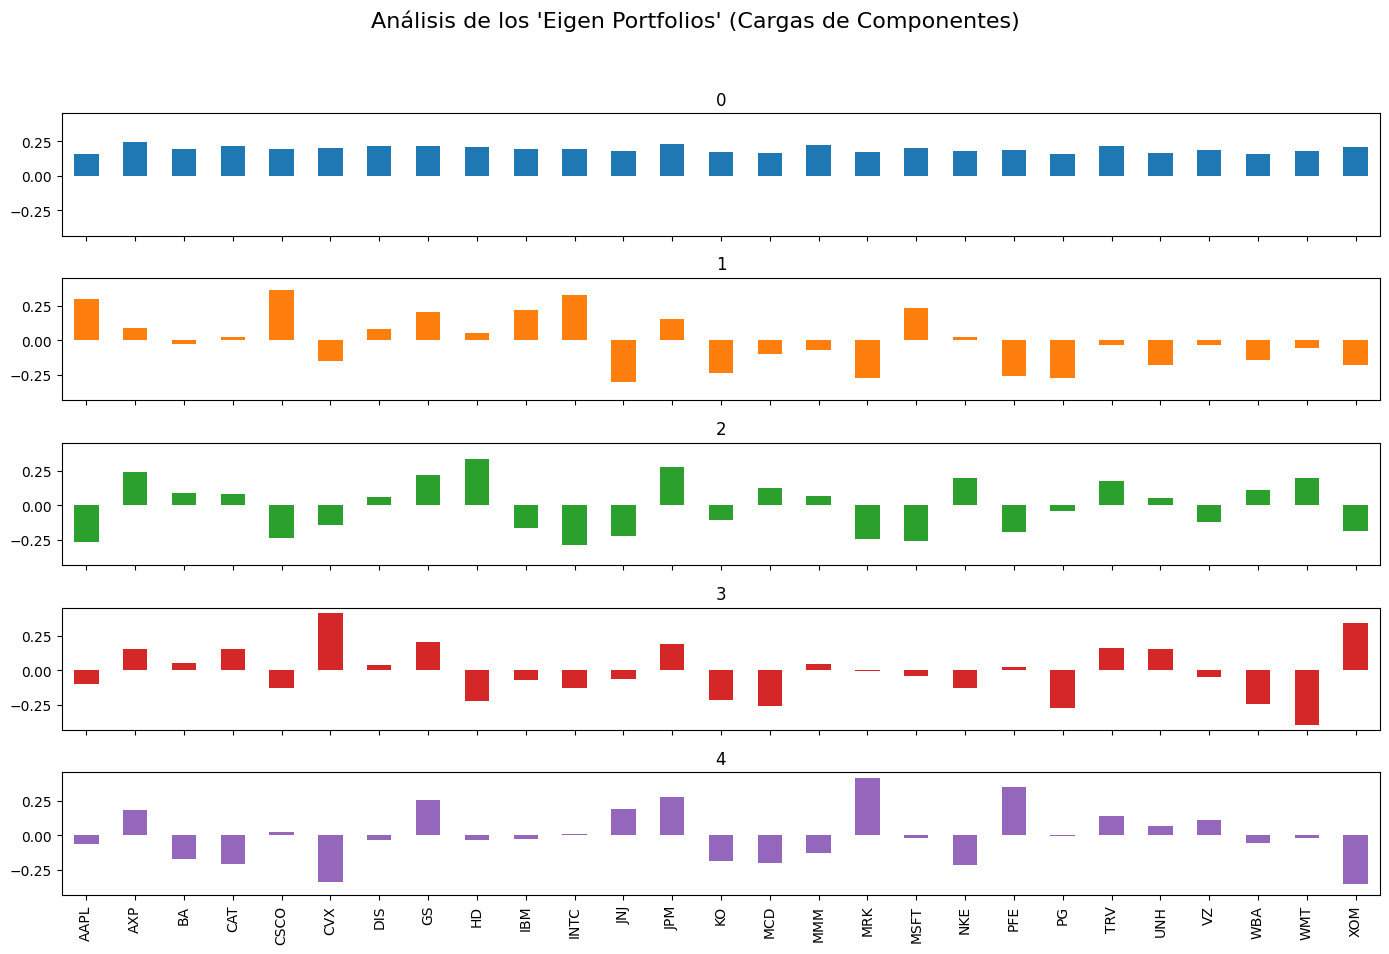

In [56]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir cuántos portafolios (componentes) queremos ver
n_portfolios = 5

# 2. Extraer los pesos (recetas) de los primeros 'n_portfolios'
# pca.components_ es un array donde cada fila es un Eigen Portfolio
# Lo ponemos en un DataFrame para que sea fácil de leer y graficar
# Estas son las "cargas" (loadings) de cada acción en el componente.
component_loadings = pd.DataFrame(pca.components_[:n_portfolios], 
                                columns=X_train.columns)

print("Cargas (pesos) de las acciones en los primeros 5 Componentes:")
print(component_loadings.head())

# 3. Graficar la "receta" (las cargas) de cada Eigen Portfolio
# Usamos .T (transponer) para que los tickers estén en el eje X
component_loadings.T.plot.bar(
    subplots=True,            # Un gráfico separado para cada portafolio
    layout=(n_portfolios, 1), # Ordenarlos verticalmente
    figsize=(14, 10),         # Tamaño de la figura
    legend=False,             # Quitar la leyenda
    sharey=True               # Compartir el mismo eje Y para comparar
)

plt.suptitle("Análisis de los 'Eigen Portfolios' (Cargas de Componentes)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajustar para el supertítulo
plt.show()

--- RESULTADO DE LA OPTIMIZACIÓN ---
El eigen portfolio #5 tiene el mayor sharpe.
Ret = 99.13%, Volatilidad = 136.84%, Sharpe = 0.72


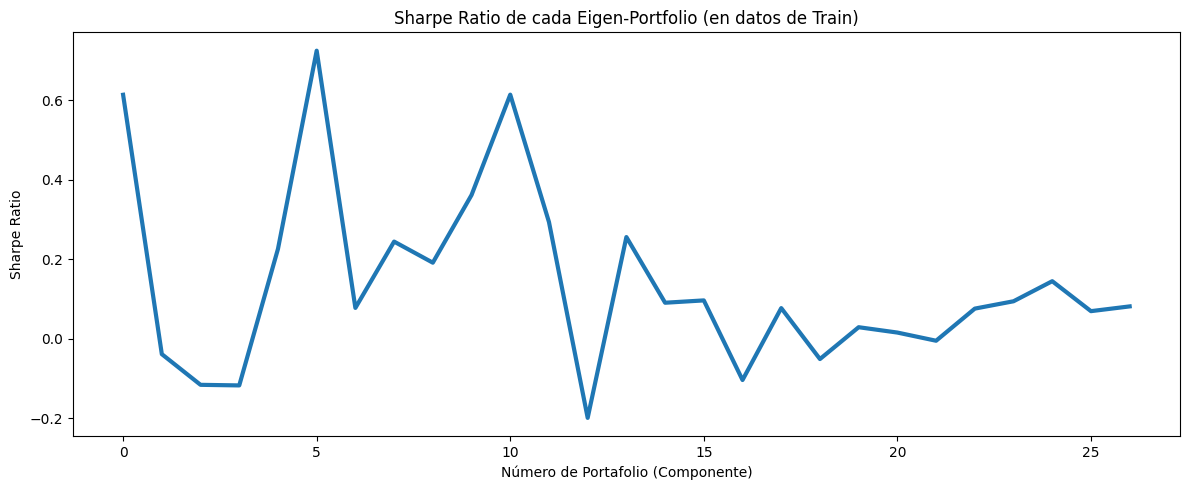

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Función Auxiliar: Calculadora de Sharpe Ratio (ESTABLE) ---
def sharpe_ratio(ts_returns, periods_per_year=252):
    n_years = ts_returns.shape[0] / periods_per_year
    
    # (i) Retorno Anualizado (Forma Aritmética Estable)
    # Simplemente promediamos los retornos diarios y los multiplicamos por 252
    annualized_return = ts_returns.mean() * periods_per_year
    
    # (ii) Volatilidad Anualizada (Esta ya era estable)
    annualized_vol = ts_returns.std() * np.sqrt(periods_per_year)
    
    # (iii) Sharpe Ratio Anualizado
    # Evitamos dividir por cero si la volatilidad es 0
    if annualized_vol == 0:
        annualized_sharpe = 0.0
    else:
        annualized_sharpe = annualized_return / annualized_vol
    
    return annualized_return, annualized_vol, annualized_sharpe

# --- 2. Función Principal: Optimización de Portafolios ---
def portfolio_optimization():
    n_portfolios = len(pca.components_)
    pcs = pca.components_
    
    annualized_ret = np.array([0.] * n_portfolios)
    annualized_vol = np.array([0.] * n_portfolios)
    sharpe_metric = np.array([0.] * n_portfolios)

    for i in range(n_portfolios):
        pc_w = pcs[i] / sum(pcs[i])
        
        eigen_prti_returns = np.dot(X_train_raw.loc[:, X_train.columns], pc_w)
        eigen_prti_returns = pd.Series(eigen_prti_returns.squeeze(), index=X_train_raw.index)
        
        # Calcular el Sharpe Ratio con la función estable
        er, vol, sharpe = sharpe_ratio(eigen_prti_returns)
        
        annualized_ret[i] = er
        annualized_vol[i] = vol
        sharpe_metric[i] = sharpe

    sharpe_metric = np.nan_to_num(sharpe_metric) # Reemplaza NaN (si hubo)
    
    # --- 3. Mostrar Resultados ---
    highest_sharpe = np.argmax(sharpe_metric)

    print('--- RESULTADO DE LA OPTIMIZACIÓN ---')
    print('El eigen portfolio #%d tiene el mayor sharpe.' % highest_sharpe)
    print('Ret = %.2f%%, Volatilidad = %.2f%%, Sharpe = %.2f' % 
        (annualized_ret[highest_sharpe]*100, 
        annualized_vol[highest_sharpe]*100, 
        sharpe_metric[highest_sharpe]))

    # Graficar todos los Sharpe Ratios
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(sharpe_metric, linewidth=3)
    ax.set_title('Sharpe Ratio de cada Eigen-Portfolio (en datos de Train)')
    ax.set_ylabel('Sharpe Ratio')
    ax.set_xlabel('Número de Portafolio (Componente)')
    plt.tight_layout()
    plt.show()

# --- 4. Ejecutar la optimización ---
portfolio_optimization()

In [57]:
# --- 1. Definir funciones auxiliares (de la guía) para obtener los pesos ---

def pc_weights():
    """
    Calcula los pesos de los vectores originales en cada uno de los componentes principales.
    Requiere un modelo PCA entrenado y con nombre 'pca'.
    """
    # pca.components_ tiene las "cargas", pero las normalizamos para que sumen 1
    weights = pd.DataFrame()
    for i in range(len(pca.components_)):
        weights[f"weights_{i}"] = pca.components_[i] / sum(pca.components_[i])
    
    # Devolvemos los pesos transpuestos (cada fila es un portafolio)
    weights = weights.values.T
    return weights

def get_weights(weights, tickers):
    """
    Convierte un array de pesos en un DataFrame bonito y ordenado.
    """
    portfolio = pd.DataFrame(data={'weights': weights.squeeze() * 100}, 
                            index=tickers)
    portfolio.sort_values(by=['weights'], ascending=False, inplace=True)
    return portfolio

# --- 2. Extraer y mostrar la receta ganadora (#5) ---

stock_tickers = rescaled_data.columns.values

# Obtener TODAS las recetas (del 0 al 26)
all_weights = pc_weights()

# Seleccionar solo la receta ganadora (la fila 5)
epf_5_weights = all_weights[5]

# Convertir la receta en una tabla legible
pesos_portfolio_5 = get_weights(weights=epf_5_weights, tickers=stock_tickers)

print("--- 'Receta' del Eigen Portfolio #5 (El Ganador) ---")
print(pesos_portfolio_5)

--- 'Receta' del Eigen Portfolio #5 (El Ganador) ---
         weights
UNH   315.090605
AAPL  157.171323
WBA   100.545775
TRV    48.894239
PG     29.072212
BA     28.713850
INTC   27.212928
CAT    21.253240
MMM    16.963229
KO     16.930086
MCD    16.426410
GS     11.324390
CSCO   10.379916
JNJ     7.717439
MSFT   -1.762222
AXP   -13.400056
IBM   -16.682272
PFE   -21.953733
JPM   -30.280061
MRK   -37.018929
HD    -41.454780
CVX   -46.085195
WMT   -60.093382
NKE   -62.622848
DIS   -66.786175
XOM   -75.776526
VZ   -233.779465


--- RESULTADO DEL BACKTESTING (Datos de Prueba) ---
Eigen-Portfolio Ganador: Ret = 65.54%, Vol = 89.50%, Sharpe = 0.73


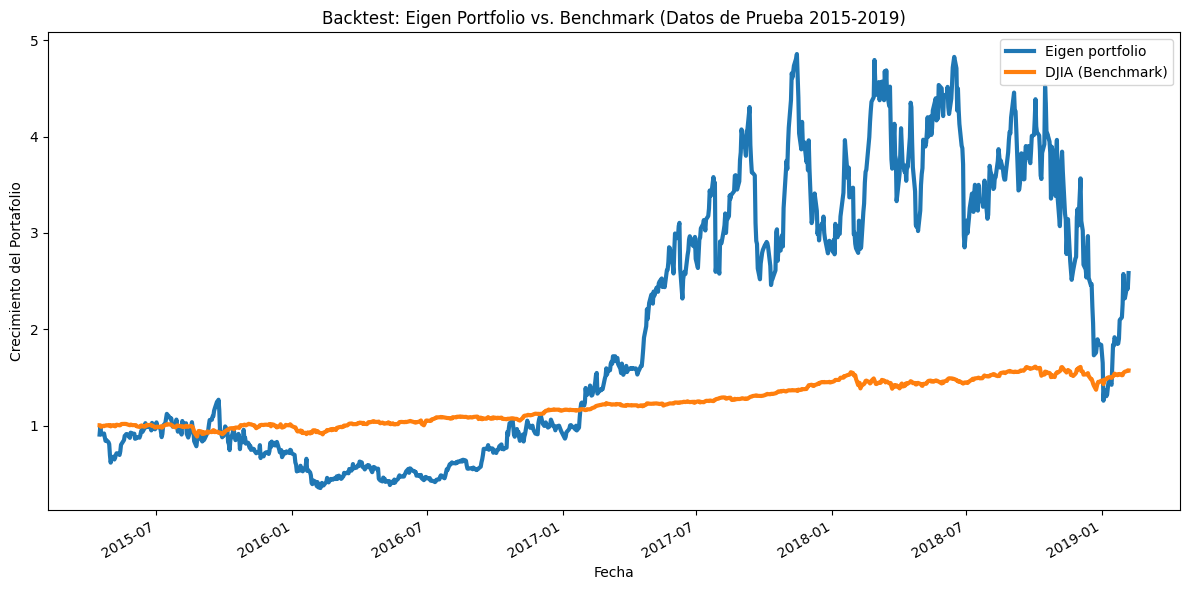

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Definir la función de Backtesting ---
# (Asegúrate de haber ejecutado la celda con la función sharpe_ratio() antes)
def backtest(eigen_weights, eigen_returns_test, benchmark_returns_test):
    """
    Compara el retorno acumulado de un Eigen Portfolio contra un benchmark.
    """
    
    # 1. Calcula los retornos de nuestra estrategia
    # Multiplica los pesos por los retornos diarios de prueba
    eigen_portfolio_returns = np.dot(eigen_returns_test, eigen_weights)
    eigen_portfolio_returns = pd.Series(eigen_portfolio_returns.squeeze(), index=eigen_returns_test.index)
    
    # 2. Calcula las métricas de nuestra estrategia en los datos de prueba
    returns, vol, sharpe = sharpe_ratio(eigen_portfolio_returns)
    print('--- RESULTADO DEL BACKTESTING (Datos de Prueba) ---')
    print('Eigen-Portfolio Ganador: Ret = %.2f%%, Vol = %.2f%%, Sharpe = %.2f' % 
          (returns * 100, vol * 100, sharpe))
    
    # 3. Prepara el DataFrame para graficar
    df_plot = pd.DataFrame({
        'Eigen portfolio': eigen_portfolio_returns, 
        'DJIA (Benchmark)': benchmark_returns_test
    }, index=eigen_returns_test.index)
    
    # 4. Grafica el retorno acumulado (usa np.cumprod para ver el crecimiento)
    (np.cumprod(df_plot + 1)).plot(figsize=(12, 6), linewidth=3)
    plt.title('Backtest: Eigen Portfolio vs. Benchmark (Datos de Prueba 2015-2019)')
    plt.ylabel('Crecimiento del Portafolio')
    plt.xlabel('Fecha')
    plt.tight_layout()
    plt.show()

# --- 2. Preparar los datos para el Backtest ---

# Los tickers (asegúrate de que esta variable existe)
stock_tickers = rescaled_data.columns.values

# Los pesos de nuestra receta ganadora (de la celda anterior)
# epf_5_weights = all_weights[5]

# Los retornos de prueba (los datos que el modelo no ha visto)
eigen_returns_test = X_test_raw.loc[:, stock_tickers]

# El benchmark: un portafolio simple con pesos iguales
num_tickers = len(stock_tickers)
benchmark_returns_test = (X_test_raw.loc[:, stock_tickers] * (1 / num_tickers)).sum(axis=1)

# --- 3. Ejecutar la prueba de fuego ---
backtest(
    eigen_weights=epf_5_weights, 
    eigen_returns_test=eigen_returns_test,
    benchmark_returns_test=benchmark_returns_test
)